# A27 拥堵概率未知，怎样通过交互学习策略？

用小型配送过程比较规则、已知模型最优规划和表格Q-learning。规划器知道真实转移概率，是信息更充分的参照，不是与学习者完全同条件。

先修：基础课 Python、NumPy、实验评价

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


### 1. 环境与动作
状态为距离终点剩余段数0—5，0是终点。动作0走稳定慢路，每次耗时2且前进一段；动作1走快路，耗时1但可能堵住原地。这里真实概率仅在环境和oracle中可见。

In [2]:
import numpy as np
import pandas as pd
SUCCESS = 0.58
STATES = 6

def step(state, action, rng):
    if state == 0:
        return (0, 0.0, True)
    advance = action == 0 or rng.random() < SUCCESS
    return (max(0, state - int(advance)), -2.0 if action == 0 else -1.0, state - int(advance) == 0)

def evaluate(policy, seeds):
    totals = []
    for seed in seeds:
        rng = np.random.default_rng(seed)
        state = 5
        total = 0.0
        for _ in range(200):
            state, reward, done = step(state, int(policy[state]), rng)
            total -= reward
            if done:
                break
        assert done
        totals.append(total)
    return np.array(totals)

### 2. 已知模型的对照
对于每段独立且相同的环境，慢路期望2分钟，快路的几何等待期望1/p分钟。只有当p大于0.5时快路更优。规则基线固定慢路。

In [3]:
oracle = np.full(STATES, int(1 / SUCCESS < 2))
safe = np.zeros(STATES, dtype=int)
assert oracle[5] == 1
print('单段理论期望：慢路2，快路', 1 / SUCCESS)

单段理论期望：慢路2，快路 1.7241379310344829


### 3. 学习者只看交互样本
Q表的每个元素是某状态采取某动作的估计回报。探索率逐渐下降；评价时停止更新和探索。每次完整训练使用独立种子，而不是训练一次换测试种子。

In [4]:
def train(seed, episodes=350):
    rng = np.random.default_rng(seed)
    q = np.zeros((STATES, 2))
    interactions = 0
    for episode in range(episodes):
        state = 5
        epsilon = max(0.05, 0.8 * (1 - episode / episodes))
        for _ in range(200):
            action = int(rng.integers(2)) if rng.random() < epsilon else int(q[state].argmax())
            nxt, reward, done = step(state, action, rng)
            interactions += 1
            target = reward + (0 if done else q[nxt].max())
            q[state, action] += 0.12 * (target - q[state, action])
            state = nxt
            if done:
                break
    return (q.argmax(axis=1), interactions, q)
seeds = list(range(2700, 2900))
runs = []
for seed in range(8):
    policy, interactions, q = train(seed)
    runs.append({'seed': seed, 'mean_time': float(evaluate(policy, seeds).mean()), 'interactions': interactions, 'policy': policy.tolist()})
pd.DataFrame(runs).to_csv(OUT_DIR / 'independent_training_runs.csv', index=False)

### 4. 汇总独立训练的波动
区间基于独立训练所得均值，用于展示训练随机性；八次运行只提供有限证据。业务评价为耗时而非只看累计reward上升。

In [5]:
scores = np.array([r['mean_time'] for r in runs])
halfwidth = 2.365 * scores.std(ddof=1) / np.sqrt(len(scores))
values = [evaluate(safe, seeds).mean(), evaluate(oracle, seeds).mean(), scores.mean()]
plt.bar(['固定慢路', '已知模型参照', 'Q-learning'], values)
plt.ylabel('每次配送分钟')
plt.tight_layout()
plt.savefig(OUT_DIR / 'policies.png')
plt.close()
metrics = {'safe_time': float(values[0]), 'oracle_time': float(values[1]), 'q_mean_time': float(scores.mean()), 'training_mean_95_t_interval': [float(scores.mean() - halfwidth), float(scores.mean() + halfwidth)], 'mean_interactions': float(np.mean([r['interactions'] for r in runs]))}
recommendation = f'本环境快路真实成功率为{SUCCESS}，已知模型参照拥有更多信息。学习策略平均耗时{scores.mean():.2f}分钟，且需要训练交互；若模型已知且状态很小，应先用规划而不是增加神经网络。'

### 保存可核验的证据
把指标写入 JSON，并用本次输出形成有条件的建议。json.dumps 把字典变成文本；不会替你判断方案是否适合现实。

In [6]:
import json
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
(OUT_DIR / '决策建议.md').write_text('# 本次计算的决策建议\n\n' + recommendation + '\n\n## 实际指标\n```json\n' + json.dumps(metrics, ensure_ascii=False, indent=2) + '\n```\n\n这些结论只适用于本例显式假设；目标权重和风险偏好由人决定。', encoding='utf-8')
print(metrics)

{'safe_time': 10.0, 'oracle_time': 8.915, 'q_mean_time': 9.593124999999999, 'training_mean_95_t_interval': [9.347622085141616, 9.838627914858382], 'mean_interactions': 2325.25}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

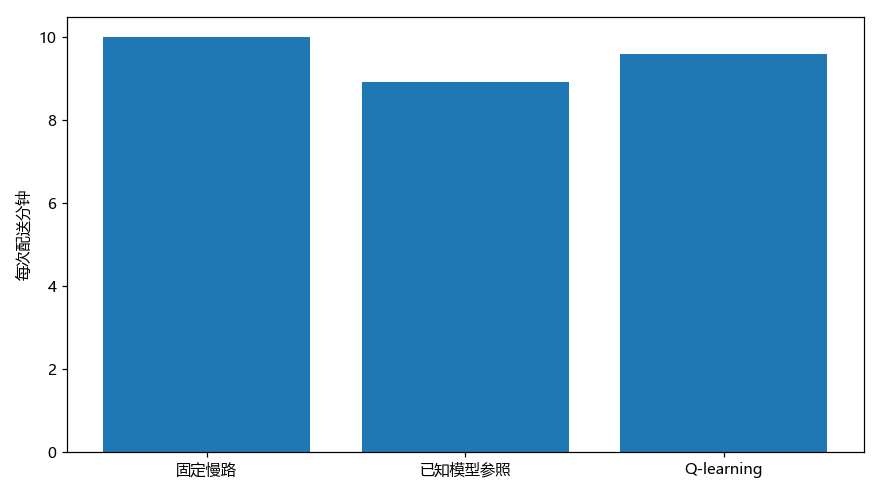

In [7]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
改变测试种子不等于独立训练。不要让oracle的信息泄漏给学习者；其优势须说明。连续不受限探索仅适用于可接受代价的模拟环境。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。